# Sampling can destabilize a continuous-time design

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/11-digital-control/notebook.ipynb)

## Goal
For $G(s)=1/(0.5s+1)$, use PI gains $k_p=2$ and $k_i=4$ with a held actuator. Apply $u_k=2(r_k-x_k)+I_k$ before updating $I_{k+1}=I_k+4T_s(r_k-x_k)$. Derive the exact sampled plant update and two-state closed-loop matrix. Compare $T_s=0.05$, $0.5$ and $1.0\,\mathrm{s}$ and find the first discrete-time stability boundary.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/11-digital-control/figures/physical-system.png)

A held voltage drives an ideal RC network. The capacitor voltage is sampled by an ideal ADC; the software controller updates the DAC once per period. Quantization, converter lag and electrical loading are omitted.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/11-digital-control/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/11-digital-control/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/11-digital-control/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/11-digital-control/figures/system-diagram.png)

The sampler, digital update order and hold are explicit. Continuous plant dynamics and sampled controller states occupy different parts of the loop.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Continuous design
The continuous PI characteristic polynomial is $0.5s^2+3s+4=0.5(s+2)(s+4)$, so its poles are stable. This does not establish the stability of a particular digital implementation.
### Exact held-input plant
Holding $u[k]$ over one sample interval gives $x[k+1]=ax[k]+bu[k]$, where $a=e^{-2T_s}$ and $b=1-a$. The explicit integral update uses the old sample error, so for zero reference,

$$
\begin{bmatrix}x[k+1]\\I[k+1]\end{bmatrix}=M(T_s)\begin{bmatrix}x[k]\\I[k]\end{bmatrix},\quad
M=\begin{bmatrix}a-2b&b\\-4T_s&1\end{bmatrix}.
$$

Changing the order of integral update and actuator computation would change this matrix.
### Unit-circle test
Discrete stability requires every eigenvalue of $M$ to lie strictly inside the unit circle. With trace $t=3a-1$ and determinant $d=3a-2+4T_s(1-a)$, the second-order Jury conditions are $1-t+d>0$, $1+t+d>0$, and $1-d>0$.
For $T_s>0$, the first expression is $4T_s(1-a)>0$. The determinant becomes one at $T_s=0.75$ s, where the conjugate pair lies on the unit circle. The remaining conditions hold up to that crossing. Thus the first stable interval is $0<T_s<0.75$ s, and the endpoint is excluded.
### Evidence and limits
Plot samples explicitly rather than connecting them as if they were continuous measurements. These results assume exact model parameters, an instantaneous computation at each sample, and no extra communication delay or actuator saturation.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
kp,ki,tau=2.,4.,.5
def closed_matrix(period):
    a=np.exp(-period/tau); b=1-a
    return np.array([[a-b*kp,b],[-ki*period,1.]])
periods=[.05,.5,1.]; responses=[]
for period in periods:
    a=np.exp(-period/tau); b=1-a
    state=np.zeros(2); time=np.arange(0,16+period/2,period); values=[]
    matrix=closed_matrix(period)
    for instant in time:
        values.append(state[0]); state=matrix@state+np.array([b*kp,ki*period])
    radius=np.max(np.abs(np.linalg.eigvals(matrix)))
    assert (radius<1)==(period<.75)
    responses.append((period,time,np.array(values)))
    print(f'Ts={period:.2f} s: spectral radius={radius:.8f}')
boundary=brentq(lambda period:np.max(np.abs(np.linalg.eigvals(closed_matrix(period))))-1,.6,.9)
assert abs(boundary-.75)<1e-10
print(f'First unit-circle crossing: {boundary:.8f} s')
grid=np.linspace(.005,1.1,300); radii=[np.max(np.abs(np.linalg.eigvals(closed_matrix(p)))) for p in grid]


Ts=0.05 s: spectral radius=0.89390714
Ts=0.50 s: spectral radius=0.60653066
Ts=1.00 s: spectral radius=1.36552727
First unit-circle crossing: 0.75000000 s


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

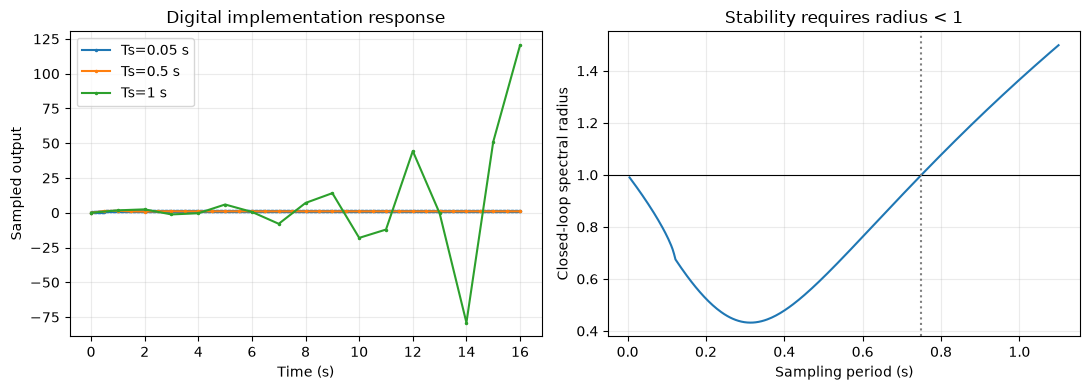

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for period,time,values in responses: axes[0].plot(time,values,'.-',label=f'Ts={period:g} s',markersize=3)
axes[0].set(xlabel='Time (s)',ylabel='Sampled output',title='Digital implementation response'); axes[0].legend()
axes[1].plot(grid,radii); axes[1].axhline(1,color='black',lw=.8); axes[1].axvline(.75,color='gray',ls=':')
axes[1].set(xlabel='Sampling period (s)',ylabel='Closed-loop spectral radius',title='Stability requires radius < 1')
fig.tight_layout()

plt.show()

## Interpret and extend
A stable continuous controller can fail after discretization. State the sampling rule and update order, then test the actual discrete closed-loop model.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)